# НИРМ3 — неделя 8: гибридные модели CNN-LSTM и CNN-Transformer с механизмом внимания

Обучение выполнено на GPU в `nirm3_week7-8_colab_training.ipynb` (Google Colab, Tesla T4); здесь —
анализ сохранённых предсказаний (`cache/results/`). Протокол оценки — недели 4.

Архитектуры (код — в ноутбуке Colab):
- **CNN-LSTM:** свёрточный стебель (2 блока «свёртка-свёртка-max-pooling», частота понижается в 4 раза:
  250 отсчётов → 62 шага) → двунаправленный LSTM (128 на направление) → attention-pooling по времени;
- **CNN-Transformer:** тот же стебель → обучаемые позиционные эмбеддинги → Transformer-энкодер (3 слоя,
  4 головы, pre-norm) → attention-pooling.

Attention-pooling — взвешенное среднее скрытых состояний по времени; веса сохраняются и на неделе 9
используются для карт внимания.

Задачи недели 8:
1. Выбор learning rate для каждой архитектуры по фолду 9.
2. Качество на тесте: 3 seed каждой архитектуры, сравнение с ResNet1d недели 7 парным бутстрепом.
3. Разрыв по полу у каждой архитектуры.
4. Стоимость: параметры и время обучения.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

SEED = 42
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
RESULTS = CACHE + 'results' + os.sep
assert glob.glob(RESULTS + '*.json'), 'скачайте results/ из Google Drive (см. ноутбук Colab)'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

meta = np.load(CACHE + 'colab_meta.npz')
Y, split, has_label, sex = meta['Y'].astype(int), meta['split'], meta['has_label'], meta['sex']
va, te = [np.where((split == s) & has_label)[0] for s in ('val', 'test')]
y_va, y_te, sex_te = Y[va], Y[te], sex[te]

RUNS = {}
for f in sorted(glob.glob(RESULTS + '*.json')):
    info = json.load(open(f))
    z = np.load(f.replace('.json', '.npz'))
    assert np.array_equal(z['val_idx'], va) and np.array_equal(z['test_idx'], te)
    RUNS[info['run_id']] = {**info, 's_val': z['s_val'], 's_test': z['s_test']}
print(f'прогонов: {len(RUNS)}')

прогонов: 19


## Протокол оценки (как на неделе 7)

In [2]:
N_BOOT = 1000
TARGET_SENS = 0.90


def auc_per_class(y, s):
    r = rankdata(s, axis=0)
    n_pos = y.sum(axis=0)
    n_neg = len(y) - n_pos
    return ((r * y).sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def macro_auc(y, s):
    return auc_per_class(y, s).mean()


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def seed_mean_ci(y, scores, metric, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    point = np.mean([metric(y, s) for s in scores], axis=0)
    boots = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        boots.append(np.mean([metric(y[idx], s[idx]) for s in scores], axis=0))
    return point, np.percentile(boots, [2.5, 97.5], axis=0)


def paired_diff(y, scores_a, scores_b, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    point = np.mean([macro_auc(y, s) for s in scores_a]) - np.mean([macro_auc(y, s) for s in scores_b])
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(np.mean([macro_auc(y[idx], s[idx]) for s in scores_a])
                     - np.mean([macro_auc(y[idx], s[idx]) for s in scores_b]))
    return point, *np.percentile(diffs, [2.5, 97.5])


def sex_gap_ci(y, scores, sx, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    f_idx, m_idx = np.where(sx == 'female')[0], np.where(sx == 'male')[0]

    def gap(fi, mi):
        g = np.mean([auc_per_class(y[fi], s[fi]) - auc_per_class(y[mi], s[mi]) for s in scores], axis=0)
        return np.append(g, g.mean())

    point = gap(f_idx, m_idx)
    boots = [gap(rng.choice(f_idx, len(f_idx)), rng.choice(m_idx, len(m_idx))) for _ in range(n)]
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    return pd.DataFrame({'female - male': point, 'CI low': lo, 'CI high': hi}, index=SUPERCLASSES + ['macro'])


def runs_like(rid):
    """Все seed той же конфигурации, что и rid."""
    cfg = {**RUNS[rid]['config'], 'seed': 0}
    return sorted(r for r, v in RUNS.items() if {**v['config'], 'seed': 0} == cfg)

## Задача 1. Выбор learning rate

Для каждого гибрида при seed 42 сравнивались lr 1e-3 и 3e-4; выбирается лучший по фолду 9, затем
обучаются seed 1 и 2.

In [3]:
lr_rows = []
for rid, r in RUNS.items():
    c = r['config']
    if c['model'] in ('cnn_lstm', 'cnn_transformer') and c['seed'] == 42:
        lr_rows.append({'model': c['model'], 'lr': c['lr'], 'val macro-AUC': r['val_macro_auc'],
                        'best_epoch': r['best_epoch'], 'run_id': rid})
lr_table = pd.DataFrame(lr_rows).sort_values(['model', 'val macro-AUC'], ascending=[True, False])
print(lr_table.drop(columns='run_id').round(4).to_string(index=False))
chosen = lr_table.groupby('model').head(1).set_index('model').run_id

          model     lr  val macro-AUC  best_epoch
       cnn_lstm 0.0010         0.9363          15
       cnn_lstm 0.0003         0.9342          15
cnn_transformer 0.0010         0.9351          15
cnn_transformer 0.0003         0.9336          15


## Задача 2. Качество на тестовом фолде 10

Сравниваются три архитектуры по 3 seed каждая: ResNet1d (лучшая конфигурация недели 7), CNN-LSTM,
CNN-Transformer; для справки — ResNet1d с настройками недели 5 и простая 1D-CNN (по одному seed).
Разность с ResNet1d — парный бутстреп по записям, метрика усреднена по seed.

In [4]:
ARCH = {
    'ResNet1d': runs_like('resnet1d_w5.0_c128-256-256_lr0.003_s42'),
    'CNN-LSTM': runs_like(chosen['cnn_lstm']),
    'CNN-Transformer': runs_like(chosen['cnn_transformer']),
}
REFERENCE = {'ResNet1d (week 5 config)': ['resnet1d_w2.5_c64-128-128_lr0.001_s42'],
             'plain 1D-CNN': ['cnn_w2.5_c32-64-128-128_lr0.001_s42']}
ARCH_COLORS = {'ResNet1d': '#4C72B0', 'CNN-LSTM': '#C98A1E', 'CNN-Transformer': '#6B4E9B'}
assert all(len(v) == 3 for v in ARCH.values())

rows = []
for name, rids in {**ARCH, **REFERENCE}.items():
    scores = [RUNS[r]['s_test'] for r in rids]
    per_seed = [macro_auc(y_te, s) for s in scores]
    point, ci = seed_mean_ci(y_te, scores, macro_auc)
    rows.append({'model': name, 'seeds': len(rids), 'params': RUNS[rids[0]]['n_params'],
                 'train_min': np.mean([RUNS[r]['train_minutes'] for r in rids]),
                 'val macro-AUC': np.mean([RUNS[r]['val_macro_auc'] for r in rids]),
                 'test macro-AUC': point, 'CI low': ci[0], 'CI high': ci[1],
                 'sd over seeds': np.std(per_seed, ddof=1) if len(rids) > 1 else np.nan})
quality = pd.DataFrame(rows).set_index('model')
print(quality.round(4).to_string())

per_class = pd.DataFrame({name: np.mean([auc_per_class(y_te, RUNS[r]['s_test']) for r in rids], axis=0)
                          for name, rids in {**ARCH, **REFERENCE}.items()}, index=SUPERCLASSES)
per_class_sd = pd.DataFrame({name: np.std([auc_per_class(y_te, RUNS[r]['s_test']) for r in rids], axis=0, ddof=1)
                             for name, rids in ARCH.items()}, index=SUPERCLASSES)
print('\nAUC по классам (среднее по seed):')
print(per_class.round(3).to_string())

base = [RUNS[r]['s_test'] for r in ARCH['ResNet1d']]
cmp_rows = []
for name in ('CNN-LSTM', 'CNN-Transformer'):
    d, lo, hi = paired_diff(y_te, [RUNS[r]['s_test'] for r in ARCH[name]], base)
    cmp_rows.append({'model': name, 'minus ResNet1d': d, 'CI low': lo, 'CI high': hi})
d, lo, hi = paired_diff(y_te, [RUNS[r]['s_test'] for r in ARCH['CNN-LSTM']],
                        [RUNS[r]['s_test'] for r in ARCH['CNN-Transformer']])
cmp_rows.append({'model': 'CNN-LSTM vs CNN-Transformer', 'minus ResNet1d': d, 'CI low': lo, 'CI high': hi})
comparison = pd.DataFrame(cmp_rows).set_index('model')
print('\nпарные разности test macro-AUC:')
print(comparison.round(4).to_string())

ens = {name: np.mean([RUNS[r]['s_test'] for r in rids], axis=0) for name, rids in ARCH.items()}
print('\nдля справки — ансамбль 3 seed (среднее предсказаний): '
      + ', '.join(f'{k} {macro_auc(y_te, v):.4f}' for k, v in ens.items()))

                          seeds   params  train_min  val macro-AUC  test macro-AUC  CI low  CI high  sd over seeds
model                                                                                                             
ResNet1d                      3  2020357    13.7422         0.9345          0.9297  0.9226   0.9359         0.0013
CNN-LSTM                      3   505350     1.2218         0.9360          0.9319  0.9251   0.9378         0.0008
CNN-Transformer               3   646022     1.6715         0.9346          0.9289  0.9219   0.9351         0.0011
ResNet1d (week 5 config)      1   510469     3.1889         0.9327          0.9295  0.9225   0.9359            NaN
plain 1D-CNN                  1   456965     0.7390         0.9342          0.9319  0.9252   0.9377            NaN

AUC по классам (среднее по seed):
      ResNet1d  CNN-LSTM  CNN-Transformer  ResNet1d (week 5 config)  plain 1D-CNN
NORM     0.949     0.952            0.951                     0.949         0.


парные разности test macro-AUC:
                             minus ResNet1d  CI low  CI high
model                                                       
CNN-LSTM                             0.0022 -0.0002   0.0045
CNN-Transformer                     -0.0008 -0.0034   0.0018
CNN-LSTM vs CNN-Transformer          0.0030  0.0014   0.0045

для справки — ансамбль 3 seed (среднее предсказаний): ResNet1d 0.9317, CNN-LSTM 0.9347, CNN-Transformer 0.9328


## Задача 3. Разрыв по полу у разных архитектур

Главный вопрос: зависит ли более низкое качество распознавания у женщин от архитектуры. Разрыв AUC
«женщины − мужчины» усреднён по seed, интервал — бутстреп внутри каждого пола. Чувствительность к MI —
при общем пороге скрининга, подобранном на фолде 9 для каждого seed.

In [5]:
gaps = {name: sex_gap_ci(y_te, [RUNS[r]['s_test'] for r in rids], sex_te) for name, rids in ARCH.items()}
gap_table = pd.concat({name: g['female - male'] for name, g in gaps.items()}, axis=1)
print('разрыв AUC женщины − мужчины (среднее по 3 seed):')
print(gap_table.round(3).to_string())
for name, g in gaps.items():
    print(f"{name}: macro {g.loc['macro', 'female - male']:+.3f} [{g.loc['macro', 'CI low']:+.3f}; "
          f"{g.loc['macro', 'CI high']:+.3f}], MI {g.loc['MI', 'female - male']:+.3f} "
          f"[{g.loc['MI', 'CI low']:+.3f}; {g.loc['MI', 'CI high']:+.3f}]")

k_mi = SUPERCLASSES.index('MI')
sens_rows = []
for name, rids in ARCH.items():
    vals = {'female': [], 'male': []}
    for r in rids:
        th = screening_thresholds(y_va, RUNS[r]['s_val'])
        for g in vals:
            m = (sex_te == g) & (y_te[:, k_mi] == 1)
            vals[g].append((RUNS[r]['s_test'][m, k_mi] >= th[k_mi]).mean())
    sens_rows.append({'model': name, 'MI sens female': np.mean(vals['female']),
                      'MI sens male': np.mean(vals['male']),
                      'gap': np.mean(vals['female']) - np.mean(vals['male'])})
mi_sens = pd.DataFrame(sens_rows).set_index('model')
print('\nчувствительность к MI при общем пороге (среднее по 3 seed):')
print(mi_sens.round(3).to_string())

разрыв AUC женщины − мужчины (среднее по 3 seed):
       ResNet1d  CNN-LSTM  CNN-Transformer
NORM     -0.017    -0.015           -0.014
MI       -0.032    -0.026           -0.030
STTC     -0.028    -0.026           -0.025
CD       -0.026    -0.029           -0.028
HYP      -0.010    -0.001            0.003
macro    -0.023    -0.019           -0.019
ResNet1d: macro -0.023 [-0.037; -0.009], MI -0.032 [-0.055; -0.011]
CNN-LSTM: macro -0.019 [-0.032; -0.006], MI -0.026 [-0.047; -0.004]
CNN-Transformer: macro -0.019 [-0.032; -0.005], MI -0.030 [-0.050; -0.008]

чувствительность к MI при общем пороге (среднее по 3 seed):
                 MI sens female  MI sens male    gap
model                                               
ResNet1d                  0.858         0.921 -0.064
CNN-LSTM                  0.891         0.924 -0.033
CNN-Transformer           0.875         0.915 -0.040


## Задача 4. Стоимость обучения

In [6]:
cost = pd.DataFrame({
    name: {'params': RUNS[rids[0]]['n_params'],
           'min per run': np.mean([RUNS[r]['train_minutes'] for r in rids]),
           's per epoch': np.mean([np.mean([h['sec'] for h in RUNS[r]['history']]) for r in rids]),
           'best epoch (mean)': np.mean([RUNS[r]['best_epoch'] for r in rids])}
    for name, rids in ARCH.items()}).T
print(cost.round(2).to_string())

                    params  min per run  s per epoch  best epoch (mean)
ResNet1d         2020357.0        13.74        41.23               18.0
CNN-LSTM          505350.0         1.22         3.67               17.0
CNN-Transformer   646022.0         1.67         5.01               17.0


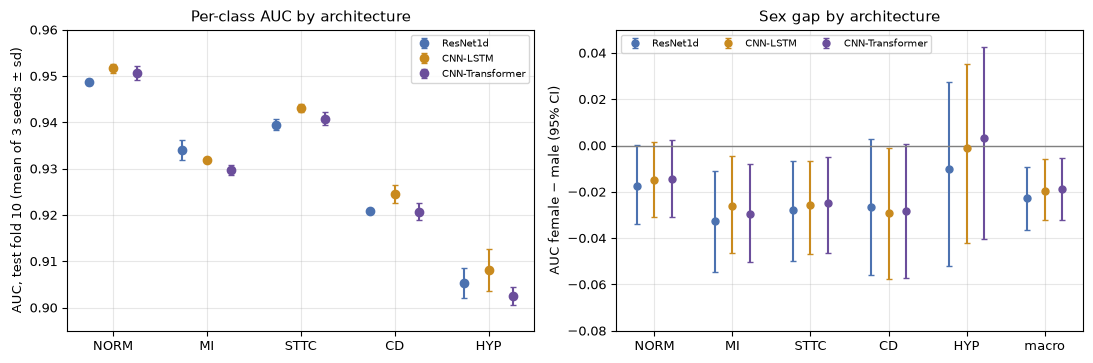

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
x = np.arange(len(SUPERCLASSES))
w = 0.26
for k, name in enumerate(ARCH):
    ax[0].errorbar(x + (k - 1) * w, per_class[name], yerr=per_class_sd[name], fmt='o', ms=6, capsize=2,
                   color=ARCH_COLORS[name], label=name)
ax[0].set_xticks(x, SUPERCLASSES)
ax[0].set(ylim=(0.895, 0.96), ylabel='AUC, test fold 10 (mean of 3 seeds ± sd)',
          title='Per-class AUC by architecture')
ax[0].legend(fontsize=7, loc='upper right')

xs = np.arange(len(SUPERCLASSES) + 1)
for k, name in enumerate(ARCH):
    g = gaps[name]
    ax[1].errorbar(xs + (k - 1) * 0.22, g['female - male'],
                   yerr=[g['female - male'] - g['CI low'], g['CI high'] - g['female - male']],
                   fmt='o', ms=5, capsize=2, color=ARCH_COLORS[name], label=name)
ax[1].axhline(0, color='gray', lw=1)
ax[1].set_xticks(xs, SUPERCLASSES + ['macro'])
ax[1].set(ylabel='AUC female − male (95% CI)', title='Sex gap by architecture')
ax[1].legend(fontsize=7, loc='upper left', ncol=3)
ax[1].set_ylim(-0.08, 0.05)
plt.tight_layout()
plt.savefig(FIG_DIR + 'w8_models_sex.png', dpi=150)
plt.show()

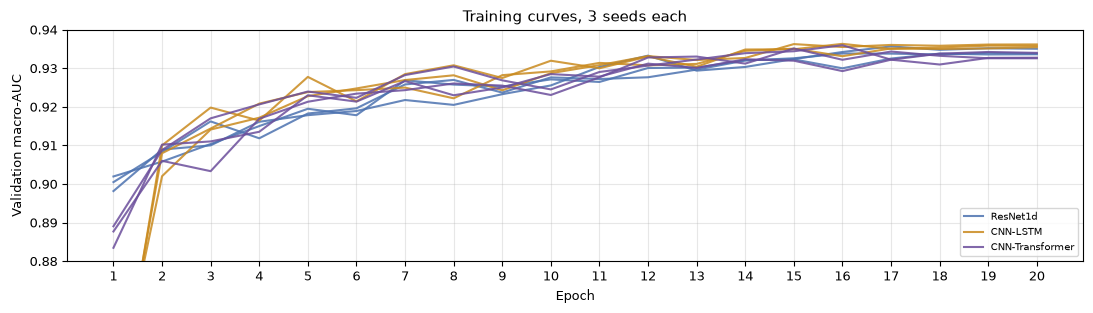

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for name, rids in ARCH.items():
    for j, r in enumerate(rids):
        h = pd.DataFrame(RUNS[r]['history'])
        ax.plot(h.epoch, h.val_macro_auc, color=ARCH_COLORS[name], lw=1.5, alpha=0.85,
                label=name if j == 0 else None)
ax.set_xticks(range(1, 21))
ax.set(ylim=(0.88, 0.94), xlabel='Epoch', ylabel='Validation macro-AUC', title='Training curves, 3 seeds each')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w8_curves.png', dpi=150)
plt.show()

In [9]:
summary = {'quality': quality.reset_index().to_dict('records'),
           'comparison': comparison.reset_index().to_dict('records'),
           'gap_macro': {n: g.loc['macro'].to_dict() for n, g in gaps.items()},
           'gap_mi': {n: g.loc['MI'].to_dict() for n, g in gaps.items()},
           'arch_runs': ARCH}
json.dump(summary, open(CACHE + 'w8_summary.json', 'w'), indent=1, default=float)
print('сохранено: w8_summary.json, w8_models_sex.png, w8_curves.png')

сохранено: w8_summary.json, w8_models_sex.png, w8_curves.png


## Выводы недели 8

**Learning rate.** Для обоих гибридов лучше 1e-3: CNN-LSTM 0.9363 против 0.9342 при 3e-4,
CNN-Transformer 0.9351 против 0.9336.

**CNN-LSTM — лучшая модель года 2, но с небольшим отрывом.** Test macro-AUC (среднее по 3 seed):
CNN-LSTM 0.932 [0.925; 0.938], ResNet1d 0.930 [0.923; 0.936], CNN-Transformer 0.929 [0.922; 0.935].
CNN-LSTM значимо лучше Transformer (+0.0030 [+0.0014; +0.0045]); перевес над ResNet1d на границе
значимости (+0.0022 [−0.0002; +0.0045]); Transformer от ResNet1d не отличается (−0.0008 [−0.0034; +0.0018]).
У CNN-LSTM и самый малый разброс между seed (0.0008). Все архитектуры укладываются в 0.003 macro-AUC —
архитектура, как и гиперпараметры на неделе 7, качество почти не ограничивает. Уровень соответствует
литературе на том же протоколе (lstm 0.927, IMLE-Net 0.922, MSW-Transformer 0.923; неделя 3).

**Transformer без предобучения CNN не превосходит** — как и предсказывала литература (неделя 3). Свёрточный
стебель здесь делает основную работу: 62 токена по 40 мс — слишком короткая последовательность, чтобы
дальние зависимости дали выигрыш.

**Разрыв по полу от архитектуры не зависит.** У всех трёх моделей macro-AUC у женщин значимо ниже:
ResNet1d −0.023 [−0.037; −0.009], CNN-LSTM −0.019 [−0.032; −0.006], CNN-Transformer −0.019 [−0.032; −0.005];
по MI −0.026…−0.032, интервалы перекрываются. Значит, источник разрыва — данные, а не устройство сети
(на неделе 6: женщин среди MI-положительных 37.7 %, пропуски MI внутри каждого подтипа). Гибриды лучше
откалиброваны для женщин: при общем пороге разрыв чувствительности к MI у CNN-LSTM −0.033 (0.891 против
0.924), у ResNet1d −0.064 — но не устраняют его.

**Стоимость.** CNN-LSTM — 505 тыс. параметров и 1.2 минуты на обучение (3.7 с на эпоху на T4) против
2.0 млн и 13.7 минуты у настроенной ResNet1d: в 4 раза меньше и в 11 раз быстрее при не худшем качестве.

**Решение для недель 9–10:** основная модель — CNN-LSTM (лучшее качество, наименьший разброс по seed,
самая дешёвая, attention-pooling даёт карты внимания для интерпретации). ResNet1d и простая CNN остаются
для сравнения и Grad-CAM.

## План на неделю 9

1. Сравнение всех моделей года 2, включая классический XGBoost недели 4, на одном тестовом фолде.
2. Интерпретация: карты внимания CNN-LSTM и CNN-Transformer, Grad-CAM для свёрточных моделей.
3. Отличаются ли карты значимости у мужчин и женщин для MI — проверка мотива года 1 на сырых ЭКГ.